## Exercise 1:

In [1]:
import numpy as np
import scipy.stats as st

method_A = np.array([
    2.1, 2.3, 2.0, 2.5, 2.2,
    2.4, 2.1, 2.3, 2.2, 2.4
])

method_B = np.array([
    2.8, 3.1, 2.7, 3.3, 2.9,
    3.2, 2.8, 3.0, 3.1, 2.9
])

# TASK 1: Descriptive statistics
n_A = len(method_A)
n_B = len(method_B)

mean_A = np.mean(method_A)
mean_B = np.mean(method_B)

std_A = np.std(method_A, ddof=1)
std_B = np.std(method_B, ddof=1)

print(f"Method A: Mean = {mean_A:.3f}, SD = {std_A:.3f}")
print(f"Method B: Mean = {mean_B:.3f}, SD = {std_B:.3f}")

# TASK 2: Welch's t-test
t_stat, p_value = st.ttest_ind(
    method_A,
    method_B,
    equal_var=False
)

# TASK 3: Mean difference
mean_difference = mean_A - mean_B

# TASK 4: Standard error and Welch degrees of freedom
var_A = std_A**2
var_B = std_B**2

se_difference = np.sqrt(var_A / n_A + var_B / n_B)

df = (
    (var_A / n_A + var_B / n_B)**2
    /
    (
        (var_A / n_A)**2 / (n_A - 1)
        + (var_B / n_B)**2 / (n_B - 1)
    )
)

# TASK 5: 95% confidence interval
confidence_interval = st.t.interval(
    confidence=0.95,
    df=df,
    loc=mean_difference,
    scale=se_difference
)

# TASK 6: Statistical significance
alpha = 0.05

print(f"\nT-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.6f}")
print(f"Mean Difference: {mean_difference:.4f}")
print(f"95% CI: {confidence_interval}")

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Method A: Mean = 2.250, SD = 0.158
Method B: Mean = 2.980, SD = 0.193

T-Statistic: -9.2462
P-Value: 0.000000
Mean Difference: -0.7300
95% CI: (np.float64(-0.8963375566016674), np.float64(-0.5636624433983326))
Reject the null hypothesis.


### Instructor Reflection Solutions

#### 1. Why is Welch's t-test appropriate?

**Answer:** Welch's t-test compares the means of two independent groups without assuming equal population variances.

It is appropriate when the groups may have different variances.

The test also assumes independent observations and is most reliable when the underlying distributions are reasonably compatible with its assumptions.

#### 2. What does the p-value indicate?

**Answer:** The p-value measures how unusual the observed test statistic would be if the null hypothesis were true.

A small p-value provides evidence against the null hypothesis.

It does not represent the probability that the null hypothesis is true.

#### 3. What does the 95% confidence interval tell us?

**Answer:** The confidence interval provides a range of plausible values for the population mean difference.

If the interval excludes zero, the corresponding two-sided test is statistically significant at the 0.05 level.

The interval also communicates the uncertainty associated with the estimated difference.

#### 4. Does statistical significance imply scientific importance?

**Answer:** No.

A statistically significant difference may be too small to matter scientifically.

Researchers should consider the magnitude of the difference, measurement uncertainty, instrument requirements, and practical consequences.

### Key Takeaway

Hypothesis tests and confidence intervals provide complementary information about differences between population means.

Statistical significance should be interpreted alongside the magnitude and scientific relevance of the estimated effect.

# Exercise 2:

In [2]:
import numpy as np
import scipy.stats as st

A = np.array([1.8, 2.1, 1.9, 2.0, 2.2, 1.7, 2.1, 2.0])
B = np.array([2.4, 2.6, 2.5, 2.7, 2.3, 2.6, 2.5, 2.8])
C = np.array([3.0, 3.2, 3.1, 3.4, 2.9, 3.3, 3.2, 3.1])

groups = [A, B, C]

# TASK 1: Descriptive statistics
for name, group in zip(["A", "B", "C"], groups):
    print(
        f"Method {name}: "
        f"Mean = {np.mean(group):.3f}, "
        f"SD = {np.std(group, ddof=1):.3f}"
    )

# TASK 2: ANOVA
f_stat, p_value = st.f_oneway(A, B, C)

print(f"\nF-Statistic: {f_stat:.4f}")
print(f"P-Value: {p_value:.6f}")

# TASK 3: Eta-squared
all_data = np.concatenate(groups)
grand_mean = np.mean(all_data)

ss_between = sum(
    len(group) * (np.mean(group) - grand_mean)**2
    for group in groups
)

ss_total = np.sum((all_data - grand_mean)**2)

eta_squared = ss_between / ss_total

print(f"Eta-Squared: {eta_squared:.4f}")

# TASK 4: Pairwise Welch's t-tests
comparisons = {
    "A vs B": (A, B),
    "A vs C": (A, C),
    "B vs C": (B, C)
}

# TASK 5: Bonferroni correction
alpha = 0.05
corrected_alpha = alpha / len(comparisons)

print(f"\nBonferroni Alpha: {corrected_alpha:.4f}")

# TASK 6: Evaluate comparisons
for name, (group1, group2) in comparisons.items():

    result = st.ttest_ind(
        group1,
        group2,
        equal_var=False
    )

    significant = result.pvalue < corrected_alpha

    print(
        f"{name}: p = {result.pvalue:.6f}, "
        f"Significant = {significant}"
    )

Method A: Mean = 1.975, SD = 0.167
Method B: Mean = 2.550, SD = 0.160
Method C: Mean = 3.150, SD = 0.160

F-Statistic: 104.4955
P-Value: 0.000000
Eta-Squared: 0.9087

Bonferroni Alpha: 0.0167
A vs B: p = 0.000006, Significant = True
A vs C: p = 0.000000, Significant = True
B vs C: p = 0.000003, Significant = True


### Instructor Reflection Solutions

#### 1. What does a statistically significant ANOVA indicate?

**Answer:** A significant ANOVA provides evidence that at least one population mean differs from the others.

However, it does not identify which specific groups differ.

#### 2. What additional information does eta-squared provide?

**Answer:** Eta-squared measures the proportion of total observed variability associated with differences between groups.

It provides an effect-size estimate that complements the ANOVA p-value.

#### 3. Why is a multiple comparison correction necessary?

**Answer:** Conducting several hypothesis tests increases the probability of obtaining at least one false-positive result.

The Bonferroni correction controls the family-wise error rate by dividing the significance level by the number of comparisons.

For three comparisons:

$$
\alpha_{\text{corrected}} = \frac{0.05}{3} \approx 0.0167
$$

#### 4. Why does a significant ANOVA not automatically establish causation?

**Answer:** ANOVA identifies statistical differences between group means, but causal conclusions depend on experimental design.

Researchers must consider whether calibration methods were randomly assigned and whether other variables could explain the observed differences.

### Key Takeaway

ANOVA tests for differences among population means, while effect sizes quantify the magnitude of those differences.

Multiple comparison corrections reduce the risk of false-positive conclusions.

## Exercise 3:

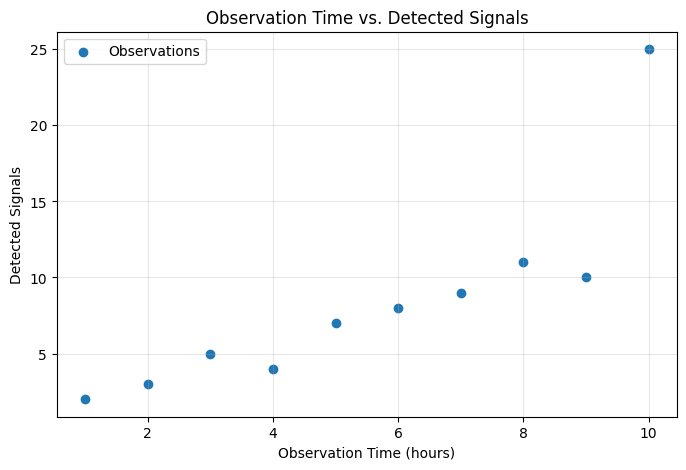

Full Dataset Correlation: 0.8435
Reduced Dataset Correlation: 0.9681

Full Dataset R-Squared: 0.7116
Reduced Dataset R-Squared: 0.9373

Regression R-Squared: 0.7116
Pearson r Squared: 0.7116


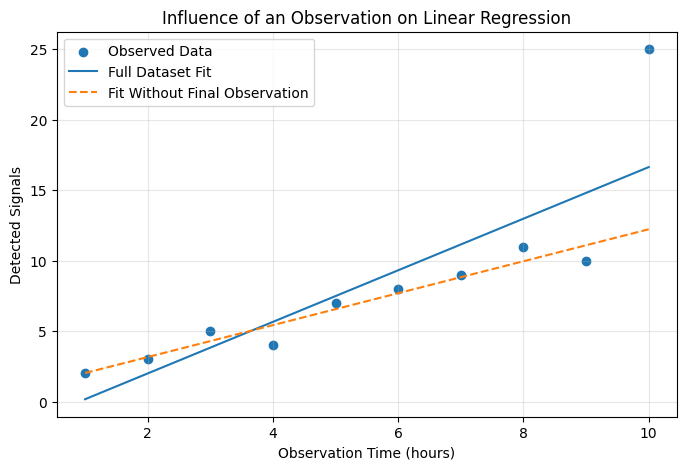

In [3]:
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

observation_time = np.arange(1, 11)

detections = np.array([
    2, 3, 5, 4, 7, 8, 9, 11, 10, 25
])

# TASK 1: Pearson correlation
r_full, p_full = st.pearsonr(
    observation_time,
    detections
)

# TASK 2: R-squared
r_squared_full = r_full**2

# TASK 3: Scatterplot
plt.figure(figsize=(8, 5))

plt.scatter(
    observation_time,
    detections,
    label="Observations"
)

plt.xlabel("Observation Time (hours)")
plt.ylabel("Detected Signals")
plt.title("Observation Time vs. Detected Signals")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# TASK 4: Correlation without final observation
r_reduced, p_reduced = st.pearsonr(
    observation_time[:-1],
    detections[:-1]
)

# TASK 5: Compare results
print(f"Full Dataset Correlation: {r_full:.4f}")
print(f"Reduced Dataset Correlation: {r_reduced:.4f}")

print(f"\nFull Dataset R-Squared: {r_squared_full:.4f}")
print(f"Reduced Dataset R-Squared: {r_reduced**2:.4f}")

# TASK 6: Fit linear regression
X = observation_time.reshape(-1, 1)

model = LinearRegression()
model.fit(X, detections)

model_r_squared = model.score(X, detections)

print(f"\nRegression R-Squared: {model_r_squared:.4f}")
print(f"Pearson r Squared: {r_squared_full:.4f}")

# TASK 7: Compare fitted lines
model_reduced = LinearRegression()

model_reduced.fit(
    observation_time[:-1].reshape(-1, 1),
    detections[:-1]
)

plt.figure(figsize=(8, 5))

plt.scatter(
    observation_time,
    detections,
    label="Observed Data"
)

plt.plot(
    observation_time,
    model.predict(X),
    label="Full Dataset Fit"
)

plt.plot(
    observation_time,
    model_reduced.predict(X),
    linestyle="--",
    label="Fit Without Final Observation"
)

plt.xlabel("Observation Time (hours)")
plt.ylabel("Detected Signals")
plt.title("Influence of an Observation on Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Instructor Reflection Solutions

#### 1. How does the final observation influence the correlation coefficient?

**Answer:** The final observation has a much larger number of detections than the other measurements.

Because it occurs at the largest observation time, it can influence both the estimated correlation and the fitted regression line.

Students should compare the correlation coefficients and fitted lines before and after removing the observation.

#### 2. Why is Pearson correlation sensitive to influential observations?

**Answer:** Pearson correlation depends on covariance and standard deviations.

Observations far from the center of the data can contribute strongly to these calculations.

An influential observation may increase or decrease the estimated correlation.

#### 3. Does a high R-squared prove that a model is scientifically correct?

**Answer:** No.

A high R-squared indicates that the fitted model explains a large proportion of observed variation in the dependent variable.

It does not establish that the model is scientifically appropriate, predicts new observations accurately, or represents a causal relationship.

#### 4. What additional evidence would be needed to establish causation?

**Answer:** Establishing causation requires additional evidence beyond correlation.

Researchers should consider:

- Potential confounding variables
- Physical mechanisms
- Experimental controls
- Independent observations
- Whether the relationship persists under different conditions

### Key Takeaway

Correlation measures linear association, while R-squared describes the explanatory fit of a regression model.

Influential observations can substantially affect both statistics.

Correlation alone does not establish causation.

## Exercise 4:

Scikit-Learn Results:
Slope: 1.5152
Intercept: 19.6667

Manual OLS Results:
Slope: 1.5152
Intercept: 19.6667

Coefficients Match: True

Predicted Temperature at 12 Hours: 37.85 °C


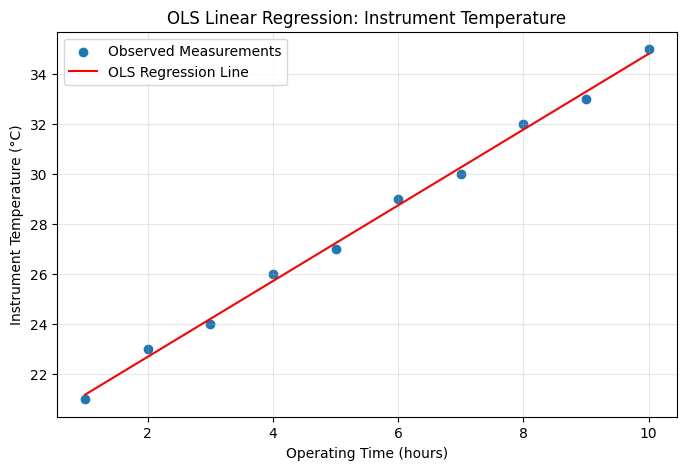

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

operating_time = np.arange(1, 11)

temperature = np.array([
    21, 23, 24, 26, 27,
    29, 30, 32, 33, 35
])

# TASK 1: Independent and dependent variables
X = operating_time.reshape(-1, 1)
y = temperature

# TASK 2: Fit linear regression
model = LinearRegression()
model.fit(X, y)

# TASK 3: Extract coefficients
slope = model.coef_[0]
intercept = model.intercept_

# TASK 4: Calculate slope manually
x_mean = np.mean(operating_time)
y_mean = np.mean(temperature)

numerator = np.sum(
    (operating_time - x_mean) * (temperature - y_mean)
)

denominator = np.sum(
    (operating_time - x_mean)**2
)

manual_slope = numerator / denominator

# TASK 5: Calculate intercept manually
manual_intercept = y_mean - manual_slope * x_mean

# TASK 6: Compare coefficients
print("Scikit-Learn Results:")
print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")

print("\nManual OLS Results:")
print(f"Slope: {manual_slope:.4f}")
print(f"Intercept: {manual_intercept:.4f}")

print(
    "\nCoefficients Match:",
    np.allclose(
        [slope, intercept],
        [manual_slope, manual_intercept]
    )
)

# TASK 7: Predict temperature at 12 hours
predicted_temperature = model.predict([[12]])[0]

print(
    f"\nPredicted Temperature at 12 Hours: "
    f"{predicted_temperature:.2f} °C"
)

# TASK 8: Plot observed data and fitted line
predicted_values = model.predict(X)

plt.figure(figsize=(8, 5))

plt.scatter(
    operating_time,
    temperature,
    label="Observed Measurements"
)

plt.plot(
    operating_time,
    predicted_values,
    color="red",
    label="OLS Regression Line"
)

plt.xlabel("Operating Time (hours)")
plt.ylabel("Instrument Temperature (°C)")
plt.title("OLS Linear Regression: Instrument Temperature")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Instructor Reflection Solutions

#### 1. What does the slope represent physically?

**Answer:** The slope represents the predicted change in instrument temperature for each additional hour of operation.

A positive slope indicates that the instrument temperature increases with operating time.

The slope has units of degrees Celsius per hour (°C/hour).

#### 2. Why does OLS minimize squared residuals?

**Answer:** Ordinary Least Squares minimizes the sum of squared differences between observed and predicted values.

Squaring the residuals:

- Prevents positive and negative errors from canceling.
- Assigns greater weight to larger prediction errors.
- Produces a mathematically tractable optimization problem.

However, squared-error minimization is sensitive to extreme observations.

#### 3. Why should the manually calculated coefficients match the scikit-learn coefficients?

**Answer:** Both calculations use the ordinary least-squares method.

For simple linear regression with an intercept, the manual formulas and scikit-learn's `LinearRegression()` solve the same optimization problem.

Small numerical differences may occur because of floating-point precision.

#### 4. What assumptions are needed to interpret the fitted relationship?

**Answer:** Important considerations include:

- The relationship is approximately linear.
- Observations are independent.
- The predictor is measured appropriately.
- The residuals do not exhibit systematic patterns.
- Important confounding variables have not been ignored when making causal claims.

For conventional statistical inference, assumptions concerning residual variance and distribution may also be important.

### Key Takeaway

Ordinary Least Squares estimates regression coefficients by minimizing squared residuals.

The slope describes how the predicted dependent variable changes with the independent variable, while the intercept gives the predicted value when the independent variable equals zero.

## Exercise 5:


Linear Regression:
RMSE: 1.8244
R-Squared: 0.9631


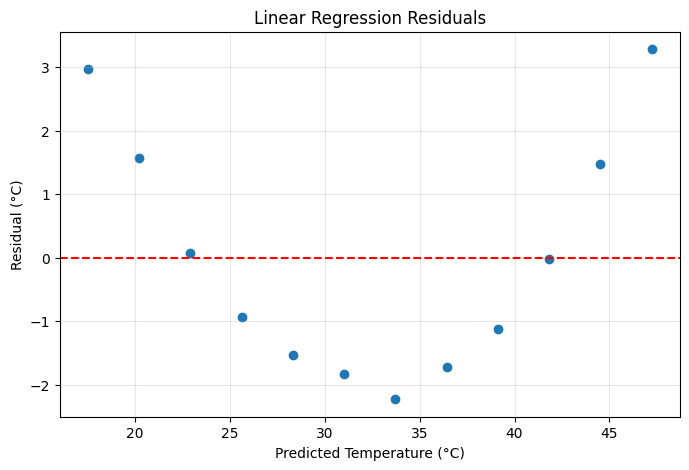


Polynomial Regression:
RMSE: 0.1302
R-Squared: 0.9998


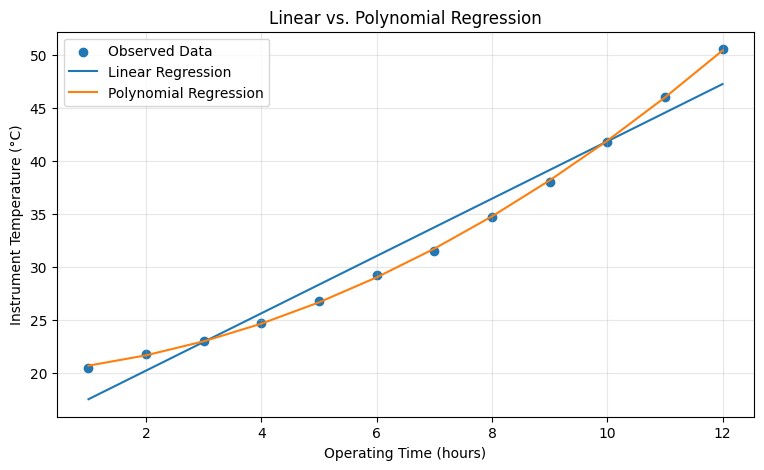


Model Comparison:
Polynomial regression has lower training RMSE.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

time = np.arange(1, 13)

temperature = np.array([
    20.5, 21.8, 23.0, 24.7, 26.8, 29.2,
    31.5, 34.7, 38.0, 41.8, 46.0, 50.5
])

X = time.reshape(-1, 1)
y = temperature

# TASK 1: Fit linear regression
linear_model = LinearRegression()
linear_model.fit(X, y)

# TASK 2: Generate predictions
linear_predictions = linear_model.predict(X)

# TASK 3: Evaluate linear regression
linear_rmse = np.sqrt(
    mean_squared_error(y, linear_predictions)
)

linear_r2 = r2_score(y, linear_predictions)

# TASK 4: Calculate residuals
linear_residuals = y - linear_predictions

print("Linear Regression:")
print(f"RMSE: {linear_rmse:.4f}")
print(f"R-Squared: {linear_r2:.4f}")

# TASK 5: Residual plot
plt.figure(figsize=(8, 5))

plt.scatter(
    linear_predictions,
    linear_residuals
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual (°C)")
plt.title("Linear Regression Residuals")

plt.grid(alpha=0.3)
plt.show()

# TASK 6: Fit polynomial regression
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_poly = poly.fit_transform(X)

polynomial_model = LinearRegression()
polynomial_model.fit(X_poly, y)

polynomial_predictions = polynomial_model.predict(X_poly)

# TASK 7: Evaluate polynomial regression
poly_rmse = np.sqrt(
    mean_squared_error(y, polynomial_predictions)
)

poly_r2 = r2_score(y, polynomial_predictions)

print("\nPolynomial Regression:")
print(f"RMSE: {poly_rmse:.4f}")
print(f"R-Squared: {poly_r2:.4f}")

# TASK 8: Compare fitted models
plt.figure(figsize=(9, 5))

plt.scatter(
    time,
    temperature,
    label="Observed Data"
)

plt.plot(
    time,
    linear_predictions,
    label="Linear Regression"
)

plt.plot(
    time,
    polynomial_predictions,
    label="Polynomial Regression"
)

plt.xlabel("Operating Time (hours)")
plt.ylabel("Instrument Temperature (°C)")
plt.title("Linear vs. Polynomial Regression")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nModel Comparison:")

if poly_rmse < linear_rmse:
    print("Polynomial regression has lower training RMSE.")
else:
    print("Linear regression has lower or equal training RMSE.")

### Instructor Reflection Solutions

#### 1. What does RMSE measure?

**Answer:** Root Mean Squared Error measures the typical magnitude of prediction errors.

RMSE is expressed in the same units as the dependent variable.

For this exercise, RMSE is measured in degrees Celsius.

A lower RMSE indicates smaller prediction errors on the evaluated dataset.

#### 2. What does a systematic pattern in the residuals indicate?

**Answer:** A systematic pattern suggests that the regression model may not adequately describe the relationship between the variables.

For example, a curved residual pattern may indicate that a linear model is missing a nonlinear relationship.

Ideally, residuals should not exhibit an obvious systematic pattern around zero.

#### 3. Why might polynomial regression outperform linear regression?

**Answer:** Polynomial regression can represent curved relationships that a straight-line model cannot capture.

In this dataset, instrument temperature increases at an accelerating rate.

A second-degree polynomial can represent this curvature more effectively than a simple linear model.

However, greater flexibility also increases the risk of overfitting.

#### 4. Does a higher training R-squared guarantee better predictions on new data?

**Answer:** No.

A more complex model may fit the training data very well but perform poorly on new observations.

This is known as overfitting.

Researchers should evaluate predictive performance using independent test data or cross-validation.

### Key Takeaway

Regression models should be evaluated using multiple diagnostics.

RMSE measures prediction error, R-squared measures explained variation, and residual plots help identify systematic model deficiencies.

A model that fits training data better does not necessarily generalize better.

## Exercise 6:

Threshold = 0.5
Accuracy: 0.750
Precision: 0.750
Recall: 0.750

Confusion Matrix:
[[6 2]
 [2 6]]

Threshold = 0.3
Accuracy: 0.812
Precision: 0.727
Recall: 1.000

Comparison:
Recall Change: 0.250
Precision Change: -0.023


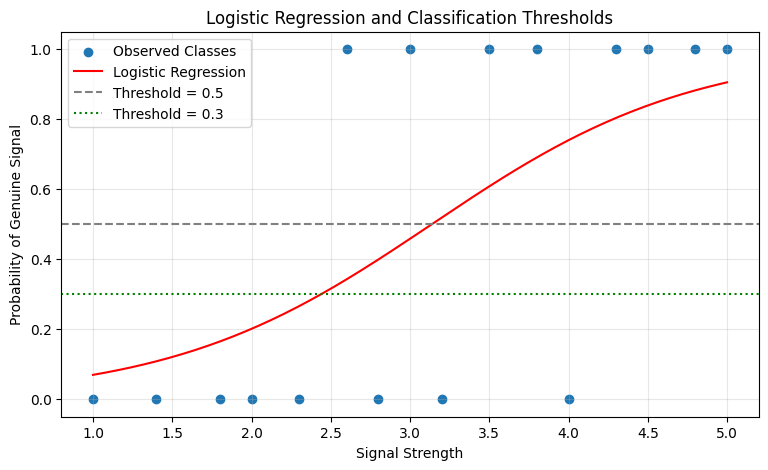

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

signal_strength = np.array([
    1.0, 1.4, 1.8, 2.0, 2.3, 2.6, 2.8, 3.0,
    3.2, 3.5, 3.8, 4.0, 4.3, 4.5, 4.8, 5.0
])

signal_class = np.array([
    0, 0, 0, 0, 0, 1, 0, 1,
    0, 1, 1, 0, 1, 1, 1, 1
])

# TASK 1: Prepare data and fit model
X = signal_strength.reshape(-1, 1)
y = signal_class

model = LogisticRegression()
model.fit(X, y)

# TASK 2: Generate predicted probabilities
probabilities = model.predict_proba(X)[:, 1]

# TASK 3: Classify using threshold = 0.5
threshold_1 = 0.5

predictions_05 = (
    probabilities >= threshold_1
).astype(int)

# TASK 4: Calculate classification metrics
accuracy_05 = accuracy_score(y, predictions_05)
precision_05 = precision_score(y, predictions_05)
recall_05 = recall_score(y, predictions_05)

print("Threshold = 0.5")
print(f"Accuracy: {accuracy_05:.3f}")
print(f"Precision: {precision_05:.3f}")
print(f"Recall: {recall_05:.3f}")

# TASK 5: Confusion matrix
cm_05 = confusion_matrix(y, predictions_05)

print("\nConfusion Matrix:")
print(cm_05)

# TASK 6: Classify using threshold = 0.3
threshold_2 = 0.3

predictions_03 = (
    probabilities >= threshold_2
).astype(int)

# TASK 7: Compare metrics
accuracy_03 = accuracy_score(y, predictions_03)
precision_03 = precision_score(y, predictions_03)
recall_03 = recall_score(y, predictions_03)

print("\nThreshold = 0.3")
print(f"Accuracy: {accuracy_03:.3f}")
print(f"Precision: {precision_03:.3f}")
print(f"Recall: {recall_03:.3f}")

print("\nComparison:")
print(f"Recall Change: {recall_03 - recall_05:.3f}")
print(f"Precision Change: {precision_03 - precision_05:.3f}")

# TASK 8: Plot probability curve
x_values = np.linspace(
    signal_strength.min(),
    signal_strength.max(),
    200
).reshape(-1, 1)

curve_probabilities = model.predict_proba(x_values)[:, 1]

plt.figure(figsize=(9, 5))

plt.scatter(
    signal_strength,
    signal_class,
    label="Observed Classes"
)

plt.plot(
    x_values,
    curve_probabilities,
    color="red",
    label="Logistic Regression"
)

plt.axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="Threshold = 0.5"
)

plt.axhline(
    0.3,
    color="green",
    linestyle=":",
    label="Threshold = 0.3"
)

plt.xlabel("Signal Strength")
plt.ylabel("Probability of Genuine Signal")
plt.title("Logistic Regression and Classification Thresholds")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Instructor Reflection Solutions

#### 1. Why is logistic regression appropriate for this problem?

**Answer:** Logistic regression is appropriate because the dependent variable is binary.

The model estimates the probability that an observation belongs to the positive class.

In this exercise:

- Class 0 represents no genuine signal.
- Class 1 represents a genuine astronomical signal.

The sigmoid function maps the model's linear predictor to a probability between 0 and 1.

#### 2. What is the difference between precision and recall?

**Answer:** Precision measures the proportion of predicted positive observations that are actually positive.

$$
\text{Precision} = \frac{TP}{TP+FP}
$$

Recall measures the proportion of actual positive observations that are correctly identified.

$$
\text{Recall} = \frac{TP}{TP+FN}
$$

where:

- TP = True Positives
- FP = False Positives
- FN = False Negatives

Precision emphasizes the reliability of positive predictions.

Recall emphasizes the ability to identify actual positive observations.

#### 3. How does lowering the classification threshold affect predictions?

**Answer:** Lowering the classification threshold makes the model more likely to classify observations as positive.

This generally increases or maintains recall because fewer actual positive observations are missed.

However, it may also increase false positives.

Precision can increase or decrease depending on the observations that change classification.

#### 4. Why might recall be more important than precision when searching for rare astronomical events?

**Answer:** Recall may be especially important when missing a genuine astronomical event has substantial scientific consequences.

A model with high recall identifies a larger proportion of actual positive events.

However, improving recall may increase false positives.

Researchers must balance the cost of missing genuine events against the resources required to investigate false detections.

### Instructor Note

The metrics calculated in this exercise describe performance on the training dataset.

They should not be interpreted as estimates of performance on independent observations.

For a more rigorous evaluation, researchers should use a separate test dataset or cross-validation.

### Key Takeaway

Logistic regression predicts probabilities for categorical outcomes.

Classification thresholds determine how probabilities are converted into class labels.

Precision, recall, and confusion matrices provide complementary information about classification performance.